## understanding variablity in historical period (1900 - 2014) using observations and historical simulations from SMILEs and CMIP data archive

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np
import os
import xarray as xr
import xcdat as xc
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm as BM
import pandas as pd
import matplotlib as mpl
import matplotlib.ticker as mticker
import netCDF4
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

In [3]:
from scipy import stats

In [4]:
mpl.rcParams['font.family'] = 'Droid Sans'
mpl.rcParams['font.size'] = 12
# Edit axes parameters
mpl.rcParams['axes.linewidth'] = 2.0
# Tick properties
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['xtick.minor.size'] = 3
mpl.rcParams['xtick.major.width'] = 1
mpl.rcParams['xtick.direction'] = 'out'
mpl.rcParams['ytick.major.size'] = 5
mpl.rcParams['ytick.minor.size'] = 3
mpl.rcParams['ytick.major.width'] = 1
mpl.rcParams['ytick.direction'] = 'out'

In [5]:
# plt.style.use('dark_background')

### Functions needed for the analysis

In [6]:
import matplotlib as m
from matplotlib.colors import BoundaryNorm as BM
import matplotlib.patches as mpatches

def plot_background(ax):
    ax.add_feature(cfeature.COASTLINE, alpha=0.9, lw=1.1)
    # ax.set_global()
    # ax.add_feature(cfeature.LAND, color='lightgray')
    # ax.add_feature(cfeature.OCEAN, color='lightgray')
    gl = ax.gridlines(draw_labels=True,
                      linewidth=1, color='gray', alpha=0.01, linestyle='--')
    gl.top_labels = False
    # gl.left_labels = False
    # gl.bottom_labels = False
    gl.right_labels = False
    gl.xlines = False
    # gl.xlocator = mticker.FixedLocator([-180, -45, 0, 45, 180])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 10, 'color': 'k'}
    gl.ylabel_style = {'size': 10, 'color': 'k'}
    return ax


def plot_maps(x, y, z, titles, labels, cmap, levels, cbar_label = 'Precip', pval = [], nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False):
    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=True, subplot_kw={'projection':ccrs.Robinson(central_longitude=180)})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax)
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        axlist[i].set_title(titles[i])
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
            axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='////', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':12})
        axlist[i].text(0.1, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
        
    norm = BM(levels, 256, extend='both')
    fig.colorbar(m.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                orientation = 'horizontal', shrink=0.4, aspect = 20, pad = 0.05, label = cbar_label)

In [7]:
from functions import preproc_funcs as funcs

In [8]:
from functions import xr_lowess

### load data

In [9]:
precip_obs = xr.open_mfdataset('/g/data/if69/as8561/data/obs_local/gpcc_v2020/precip.mon.total.1x1.v2020.nc').precip.load()
precip_obs

<xarray.DataArray 'precip' (time: 1548, lat: 180, lon: 360)>
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]], dtype=float32)
Coordinates:
  * lat      (lat) float32 89.5 88.5 87.5 86.5 85.5 ... -86.5 -87.5 -88.5 -89.5
  * lon      (lon) float32 0.5 1.5 2.5 3.5 4.5 ... 355.5 356.5 357.5 358.5 359.5
  * time     (time) datetime64[ns] 1891-01-01 1891-02-01 ... 2019-12-01
Attributes:
    long_name:     GPCC Monthly total of precipitation
    statistic:     Total
    valid_range:   [   0. 8000.]
    parent_stat:   Observations
    var_desc:      Precipitation
    units:         mm
    level:         Surface
    dataset:       GPCC Precipitation 1.0degree V2020 Full Reanalysis
    actual_range:  [   0.   4830.39]

In [10]:
ts_obs_anom = xr.open_dataset('/g/data/if69/as8561/data/obs_local/HadCRUT.5.0.1.0.analysis.anomalies.ensemble_mean.nc').tas_mean.rename(dict(longitude='lon', latitude='lat'))
ts_obs_anom

<xarray.DataArray 'tas_mean' (time: 2079, lat: 36, lon: 72)>
[5388768 values with dtype=float64]
Coordinates:
  * time         (time) datetime64[ns] 1850-01-16T12:00:00 ... 2023-03-16T12:...
  * lat          (lat) float64 -87.5 -82.5 -77.5 -72.5 ... 72.5 77.5 82.5 87.5
  * lon          (lon) float64 -177.5 -172.5 -167.5 -162.5 ... 167.5 172.5 177.5
    realization  int64 ...
Attributes:
    long_name:     blended air_temperature_anomaly over land with sea_water_t...
    units:         K
    cell_methods:  area: mean (interval: 5.0 degrees_north 5.0 degrees_east) ...

In [11]:
precip_rean = xr.open_dataset('/g/data/if69/as8561/data/20CR/precip/prate.mon.mean.nc')

In [12]:
sst_obs = xc.open_dataset('/g/data/if69/as8561/data/obs_local/sst_obs.nc', lon_orient=(0,360)).sst
sst_obs = sst_obs.rename(dict(latitude='lat', longitude='lon'))
sst_obs

<xarray.DataArray 'sst' (time: 1837, lat: 180, lon: 361)>
array([[[-1000. , -1000. , -1000. , ..., -1000. , -1000. , -1000. ],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        ...,
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan]],

       [[-1000. , -1000. , -1000. , ..., -1000. , -1000. , -1000. ],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        ...,
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan]],

       [[-1000. , -1000. , -1000. , ..., -1000. , -1000. , -1000. ],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        [-1000. , -1000. , -1000. , ..., -1000. , -1000. , -1000. ],
        ...,
...
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan]],

       [[-1000. ,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        [   -1.8,    -1.8, -1000. , ...,    -1.8,    -1.8,    -1.8],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        ...,
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan]],

       [[-1000. , -1000. , -1000. , ..., -1000. , -1000. , -1000. ],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        [-1000. , -1000. ,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        ...,
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan]]],
      dtype=float32)
Coordinates:
  * time     (time) object 1870-01-16 11:59:59.505615 ... 2023-01-16 12:00:00
  * lat      (lat) float32 89.5 88.5 87.5 86.5 85.5 ... -86.5 -87.5 -88.5 -89.5
  * lon      (lon) float32 0.5 1.5 2.5 3.5 4.5 ... 356.5 357.5 358.5 359.5 359.5
Attributes:
    standard_name:  sea_surface_temperature
    long_name:      sst
    units:          C
    cell_methods:   time: lat: lon: mean

In [13]:
sst_obs_anom = funcs.calc_anom(sst_obs, sst_obs.sel(time = slice('1960', '1990')))
# sst_obs_anom = sst_obs_anom.sel(time = sst_obs_anom.time.dt.month.isin([9,10,11,12,1,2])).resample(time='AS-JUN').mean('time')
sst_obs_anom = sst_obs_anom.resample(time='AS-JUN').mean('time')
weights_sst_obs = np.cos(np.deg2rad(sst_obs.lat))
nino34_obs = funcs.detrend_separate_check(sst_obs_anom.sel(lat=slice(5,-5), lon = slice(-170+360, -120+360)).weighted(weights_sst_obs).mean(('lat', 'lon')), period=15, dim='time')


In [14]:
import seaborn as sns

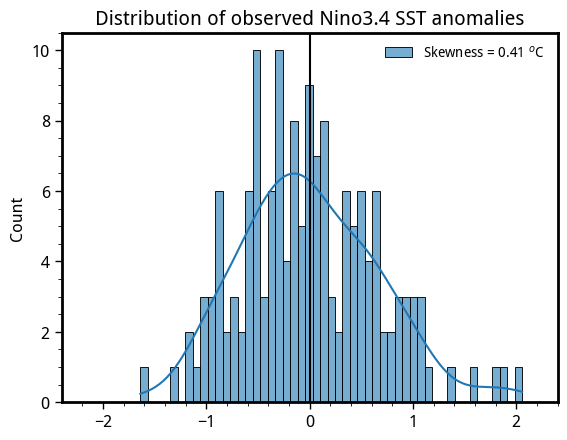

In [15]:
sns.histplot(nino34_obs, bins=51, kde=True, alpha=0.6, color='tab:blue', label=f'Skewness = {np.round(stats.skew(nino34_obs), 3)} $^o$C')
plt.axvline(0.0, color='k', ls='-')
plt.xlim(-2.4, 2.4)
plt.minorticks_on()
plt.title('Distribution of observed Nino3.4 SST anomalies')
plt.legend(frameon=False, fontsize=10)

[Text(1, 0, 'strong-LN'),
 Text(2, 0, 'LN'),
 Text(3, 0, 'NEUT'),
 Text(4, 0, 'EN'),
 Text(5, 0, 'strong-EN')]

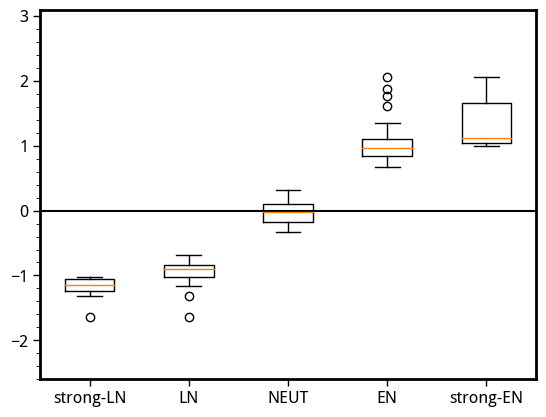

In [16]:
thres = nino34_obs.std('time')
plt.boxplot([nino34_obs.where(nino34_obs < -1.5*thres, drop=True),
             nino34_obs.where(nino34_obs < -thres, drop=True),
             nino34_obs.where((nino34_obs > -0.5*thres) & (nino34_obs < 0.5*thres), drop=True),
             nino34_obs.where(nino34_obs > thres, drop=True),
             nino34_obs.where(nino34_obs > 1.5*thres, drop=True)])


plt.ylim(-2.6, 3.1)
plt.axhline(0.0, color='k', ls='-')
plt.minorticks_on()
plt.tick_params(axis='x', which='minor', bottom=False)
plt.gca().set_xticklabels(['strong-LN', 'LN', 'NEUT', 'EN', 'strong-EN'])

In [17]:
import regionmask

In [18]:
land_mask = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(precip_obs)
ar6_mask = regionmask.defined_regions.ar6.land.mask_3D(precip_obs.where(land_mask))

In [19]:
precip_obs_anom = funcs.calc_anom(precip_obs, precip_obs.sel(time = slice('1960', '1990')))
# precip_obs_anom = precip_obs_anom.sel(time = precip_obs_anom.time.dt.month.isin([9,10,11,12,1])).resample(time = 'AS-JUN').mean('time')
precip_obs_anom = precip_obs_anom.resample(time = 'AS-JUN').mean('time')

In [20]:
weights_precip_obs = np.cos(np.deg2rad(precip_obs.lat))
reg_anom = precip_obs_anom.where(ar6_mask.isel(region=15)).weighted(weights_precip_obs).mean(('lat', 'lon'))

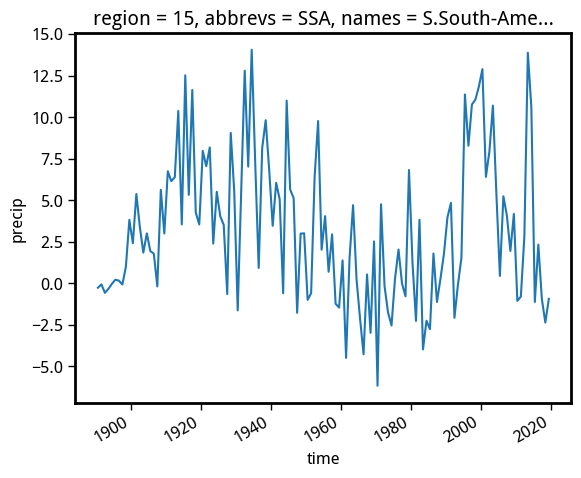

In [21]:
reg_anom.plot()

In [22]:
reg_det = funcs.detrend_separate_check(reg_anom, dim='time', period=15)
reg_std = reg_det/reg_det.sel(time = slice('1900', '2000')).std('time')

In [23]:
reg_det = reg_det.sel(time = slice('1900', '2014'))
nino34_obs = nino34_obs.sel(time = slice('1900', '2014'))
reg_det['time'] = nino34_obs['time']

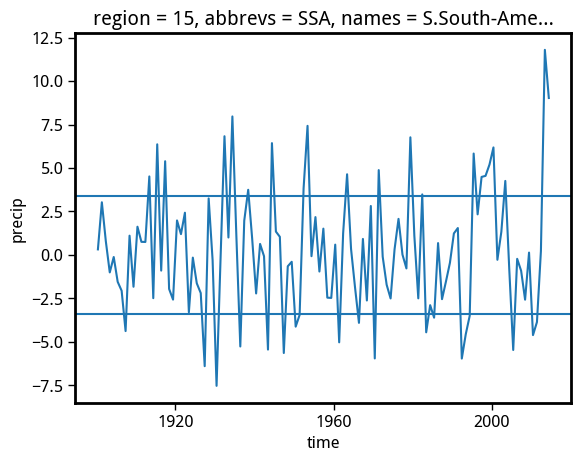

In [24]:
reg_det.plot()
plt.axhline(reg_det.sel(time = slice('1900', '2000')).std())
plt.axhline(-reg_det.sel(time = slice('1900', '2000')).std())

In [25]:
def calc_tele(precip: xr.DataArray, nino34: xr.DataArray, start_year: int, end_year: int):
    if not isinstance(precip, xr.DataArray) or not isinstance(nino34, xr.DataArray):
        raise TypeError("'xr.DataArray' input is required, not the %s" % (type(precip)))
    duration = end_year - start_year
    res = stats.linregress(nino34.sel(time=slice(str(start_year), str(end_year))), precip.sel(time=slice(str(start_year), str(end_year))))
    return res.slope, res.pvalue, duration


def get_all_tele(precip: xr.DataArray, nino34: xr.DataArray, initial_dur: int = 10):
    if not isinstance(precip, xr.DataArray) or not isinstance(nino34, xr.DataArray):
        raise TypeError("'xr.DataArray' input is required, not the %s" % (type(precip)))
    start_years = np.arange(1900, 2016, 2)
    end_years = np.arange(1900, 2016, 2)
    stat = np.empty((len(start_years), len(end_years)))
    pval = np.empty((len(start_years), len(end_years)))
    duration = np.empty((len(start_years), len(end_years)))
    for i in range(len(start_years)):
        for j in range(len(end_years)):
            if end_years[j] < start_years[i] + initial_dur:
                stat[i, j], pval[i, j], duration[i, j] = np.NaN, np.NaN, np.NaN
            else:
                stat[i, j], pval[i, j], duration[i, j] = calc_tele(precip, nino34, start_years[i], end_years[j])
        # print(f"Completed {start_years[i]}", end='\r')
    return start_years, end_years, stat, pval, duration


In [26]:
calc_tele(reg_std, nino34_obs, start_year=1900, end_year=2014)

(0.06380839022679109, 0.678174293076554, 114)

In [27]:
# reg_std.to_netcdf('./data/eaus_obs.nc')
# nino34_obs.to_netcdf('./data/nino34_obs.nc')

In [28]:
# funcs.get_regr_1d(nino34_obs.sel(time = slice('1900', '2000')), reg_std.sel(time = slice('1900', '2000')))

In [29]:
sy, ey, sl, p, dur = get_all_tele(reg_std, nino34_obs, initial_dur=30)

(1900.0, 1970.0)

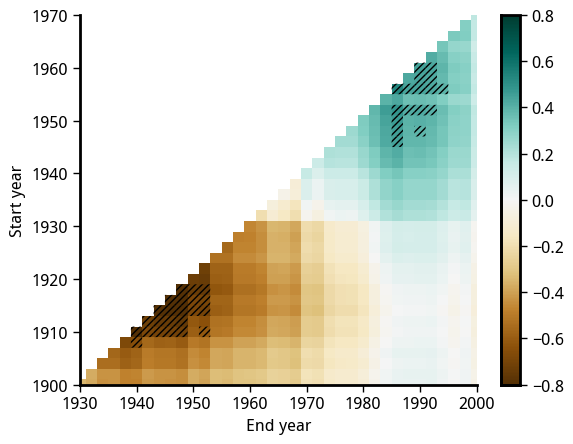

In [30]:
x, y = np.meshgrid(ey, sy)
cf = plt.pcolormesh(ey, sy, sl, cmap='BrBG', vmin=-0.8, vmax=0.8)
z = np.ma.masked_greater(p, 0.05)
plt.pcolor(x,y, z, hatch='/////', alpha=0.)
plt.colorbar(cf)
sns.despine()
# plt.gca().invert_yaxis()
plt.gca().invert_xaxis()
plt.ylabel('Start year')
plt.xlabel('End year')
plt.xlim(1930, 2000)
plt.ylim(1900, 1970)
# plt.savefig('./images/method/ssa_reg_temporal_tele_variation.png', dpi=300, bbox_inches='tight')

Text(0.5, 0, 'Regression strength [$\\sigma_P$ / degC]')

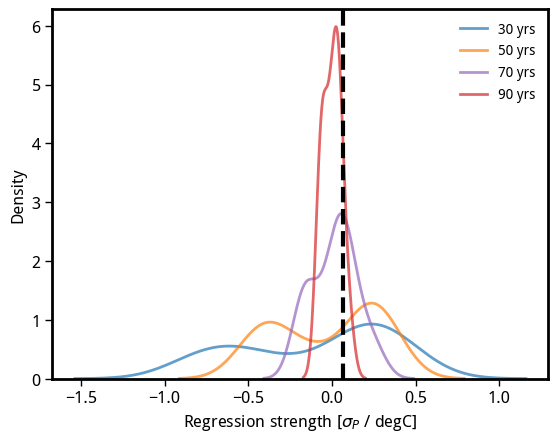

In [31]:
# sns.histplot(sl[dur==30], element='step', kde=True, bins=31, alpha=0.3, color='tab:blue', label='30 yrs')
# sns.histplot(sl[dur==50], element='step', kde=True, bins=31, alpha=0.3, color='tab:orange', label='50 yrs')
# sns.histplot(sl[dur==70], element='step', kde=True, bins=31, alpha=0.3, color='tab:purple', label='70 yrs')
# sns.histplot(sl[dur==90], element='step', kde=True, bins=31, alpha=0.3, color='tab:red', label='90 yrs')
# plt.axvline(sl[dur==100], color='k', ls='--', lw=3.0)

sns.kdeplot(sl[dur==30], alpha=0.7, lw=2.0, color='tab:blue', label='30 yrs')
sns.kdeplot(sl[dur==50], alpha=0.7, lw=2.0, color='tab:orange', label='50 yrs')
sns.kdeplot(sl[dur==70], alpha=0.7, lw=2.0, color='tab:purple', label='70 yrs')
sns.kdeplot(sl[dur==90], alpha=0.7, lw=2.0, color='tab:red', label='90 yrs')
plt.axvline(sl[dur==114], color='k', ls='--', lw=3.0)
plt.legend(frameon=False, fontsize=10)
plt.xlabel('Regression strength [$\sigma_P$ / degC]')
# plt.title('N. Australia [OBS]')

# plt.savefig('./images/method/ssa_reg_sample_size_effects.png', dpi=300, bbox_inches='tight')

In [32]:
sl[dur == 30]

array([-0.34812236, -0.37165471, -0.5402329 , -0.56397591, -0.67763468,
       -0.81055446, -0.72182399, -0.81490617, -0.79783302, -0.90324418,
       -0.72801933, -0.72476957, -0.52839045, -0.56112165, -0.48200712,
       -0.4653057 , -0.20008398, -0.08122227, -0.03803075, -0.09400134,
        0.15684036,  0.14355659,  0.214623  ,  0.24109046,  0.25278522,
        0.31982013,  0.38667697,  0.39738176,  0.52736787,  0.42851259,
        0.44785996,  0.4164244 ,  0.34339354,  0.33087559,  0.31172825,
        0.17515932,  0.14014732,  0.12822226,  0.13537617,  0.15668218,
        0.18411328,  0.2129251 ,  0.20330039])

In [33]:
np.std(sl[dur==30]), np.std(sl[dur==90])

(0.44150073668736667, 0.0522907810056873)

In [34]:
np.shape(sl[dur==30])

(43,)

In [35]:
np.max(sl[dur==30]), np.min(sl[dur==30])

(0.527367865997224, -0.9032441801940937)

In [36]:
def calc_tele_diversity(precip, nino34, duration=30, gap=2):
    if np.nansum(precip) != 0:
        i = 0
        regr_arr = []
        pval_arr = []
        ey=[]
        while i < (len(precip.time) - duration):
            regr_arr.append(funcs.get_regr(nino34.isel(time = slice(i,i+duration)), precip.isel(time=slice(i,i+duration)), dim='time').data)
            pval_arr.append(funcs.get_pval(nino34.isel(time = slice(i,i+duration)), precip.isel(time=slice(i,i+duration)), dim='time').data)
            ey.append(float(nino34.time.dt.year[i+duration]))
            print(f'Completed ey: {float(nino34.time.dt.year[i+duration])}', end='\r')
            i += gap

        out30 = xr.Dataset(
            data_vars=dict(
                regr=(["ey", "lat", "lon"], np.concatenate([arr[np.newaxis, ...] for arr in regr_arr])),
                pval=(["ey", "lat", "lon"], np.concatenate([arr[np.newaxis, ...] for arr in pval_arr])),
            ),
            coords=dict(
                lon = ("lon", precip.lon.to_numpy()),
                lat = ("lat", precip.lat.to_numpy()),
                ey = ("ey", ey),
            ),
            )

        return out30


def calc_tele_diversity_winds(wind, nino34, duration=30, gap=2):
    if np.nansum(wind.uwnd) != 0:
        i = 0
        uregr_arr = []
        vregr_arr = []
        ey=[]
        while i < (len(wind.time) - duration):
            out = funcs.get_regr(nino34.isel(time = slice(i,i+duration)), wind.isel(time=slice(i,i+duration)), dim='time')
            uregr_arr.append(out.uwnd.data)
            vregr_arr.append(out.vwnd.data)
            ey.append(float(nino34.time.dt.year[i+duration]))
            print(f'Completed ey: {float(nino34.time.dt.year[i+duration])}', end='\r')
            i += gap

        out30 = xr.Dataset(
            data_vars=dict(
                uregr=(["ey", "lat", "lon"], np.concatenate([arr[np.newaxis, ...] for arr in uregr_arr])),
                vregr=(["ey", "lat", "lon"], np.concatenate([arr[np.newaxis, ...] for arr in vregr_arr])),
            ),
            coords=dict(
                lon = ("lon", wind.lon.to_numpy()),
                lat = ("lat", wind.lat.to_numpy()),
                ey = ("ey", ey),
            ),
            )

        return out30

In [37]:
def calc_tele_diversity1d(precip, nino34, duration=30, gap=2):
    if np.nansum(precip) != 0:
        i = 0
        regr_arr = []
        pval_arr = []
        ey=[]
        while i < (len(precip.time) - duration):
            regr_arr.append(funcs.get_regr(nino34.isel(time = slice(i,i+duration)), precip.isel(time=slice(i,i+duration)), dim='time').data)
            pval_arr.append(funcs.get_pval(nino34.isel(time = slice(i,i+duration)), precip.isel(time=slice(i,i+duration)), dim='time').data)
            ey.append(float(nino34.time.dt.year[i+duration]))
            print(f'Completed ey: {float(nino34.time.dt.year[i+duration])}', end='\r')
            i += gap

        out30 = xr.Dataset(
            data_vars=dict(
                regr=(["ey"], np.concatenate([arr[np.newaxis, ...] for arr in regr_arr])),
                pval=(["ey"], np.concatenate([arr[np.newaxis, ...] for arr in pval_arr])),
            ),
            coords=dict(
                ey = ("ey", ey),
            ),
            )

        return out30


In [38]:
# precip_obs_det = funcs.detrend_separate_check(precip_obs_anom, dim='time', period=15)
# precip_obs_det = precip_obs_anom - precip_obs_anom.rolling(time=9).mean('time')
precip_obs_det = funcs.detrend_rolling_window(precip_obs_anom, window_size=15)
precip_obs_std = precip_obs_det/precip_obs_det.sel(time = slice('1900', '2000')).std('time')

In [39]:
ts_obs_det = funcs.detrend_rolling_window(ts_obs_anom.bfill('time').resample(time='AS-JUN').mean('time'), window_size=15)

In [40]:
precip_rean_anom = funcs.calc_anom(precip_rean, precip_rean.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time')

In [41]:
psl_rean = xr.open_dataset('/g/data/if69/as8561/data/20CR/slp/prmsl.mon.mean.nc').prmsl
psl_rean_anom = funcs.calc_anom(psl_rean, psl_rean.sel(time = slice('1960', '1990'))).resample(time='AS-JUN').mean('time')

In [42]:
zg500_rean = xr.open_dataset('/g/data/if69/as8561/data/20CR/hgt/hgt.mon.mean_500.nc').hgt
zg500_rean_anom = funcs.calc_anom(zg500_rean, zg500_rean.sel(time = slice('1960', '1990'))).resample(time='AS-JUN').mean('time')

In [43]:
psl_rean_det = funcs.detrend_rolling_window(psl_rean_anom, window_size=15)

In [44]:
zg500_rean_det = funcs.detrend_rolling_window(zg500_rean_anom, window_size=15)

In [45]:
# uwnd_rean = xr.open_dataset('/g/data/if69/as8561/data/20CR/wind/uwnd.10m.mon.mean.nc').uwnd
# vwnd_rean = xr.open_dataset('/g/data/if69/as8561/data/20CR/wind/vwnd.10m.mon.mean.nc').vwnd

# wind_rean = xr.merge([uwnd_rean, vwnd_rean])
# wind_rean

wind_rean = xr.open_dataset('/g/data/if69/as8561/data/20CR/wind/wind.mon.mean_100.nc')

In [46]:
wind_rean_anom = funcs.calc_anom(wind_rean, wind_rean.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time')
wind_rean_det = funcs.detrend_rolling_window(wind_rean_anom, window_size=15)

In [47]:
# precip_rean_det = funcs.detrend_separate_check(precip_rean_anom, dim='time', period=15)
precip_rean_det = funcs.detrend_rolling_window(precip_rean_anom.prate, window_size=15)
precip_rean_std = precip_rean_det/precip_rean_det.sel(time = slice('1900', '2000')).std('time')

In [48]:
precip_obs_std = precip_obs_std.sel(time = slice('1900', '2014'))
nino34_obs = nino34_obs.sel(time = slice('1900', '2014'))
precip_obs_std['time'] = nino34_obs['time']

In [49]:
ts_obs_det = ts_obs_det.sel(time = slice('1900', '2014'))
# nino34_obs = nino34_obs.sel(time = slice('1900', '2014'))
ts_obs_det['time'] = nino34_obs['time']

In [ ]:
precip_rean_std = precip_rean_std.sel(time = slice('1900', '2014'))
# nino34_obs = nino34_obs.sel(time = slice('1900', '2014'))
precip_rean_std['time'] = nino34_obs['time']

In [51]:
psl_rean_det = psl_rean_det.sel(time = slice('1900', '2014'))
psl_rean_det['time'] = nino34_obs['time']

In [52]:
zg500_rean_det = zg500_rean_det.sel(time = slice('1900', '2014'))
zg500_rean_det['time'] = nino34_obs['time']

In [53]:
wind_rean_det = wind_rean_det.sel(time = slice('1900', '2014'))
wind_rean_det['time'] = nino34_obs['time']

In [54]:
long_regr = funcs.get_regr(nino34_obs, precip_obs_std, dim='time')
long_pval = funcs.get_pval(nino34_obs, precip_obs_std, dim='time')

In [55]:
long_regr_ts = funcs.get_regr(nino34_obs, ts_obs_det, dim='time')
long_pval_ts = funcs.get_pval(nino34_obs, ts_obs_det, dim='time')

In [56]:
long_regr_rean = funcs.get_regr(nino34_obs, precip_rean_std, dim='time')
long_pval_rean = funcs.get_pval(nino34_obs, precip_rean_std, dim='time')

In [57]:
long_regr_rean_psl = funcs.get_regr(nino34_obs, psl_rean_det, dim='time')
long_pval_rean_psl = funcs.get_pval(nino34_obs, psl_rean_det, dim='time')

In [58]:
long_regr_rean_zg500 = funcs.get_regr(nino34_obs, zg500_rean_det, dim='time')
long_pval_rean_zg500 = funcs.get_pval(nino34_obs, zg500_rean_det, dim='time')

In [59]:
long_regr_rean_wind = funcs.get_regr(nino34_obs, wind_rean_det, dim='time')
# long_pval_rean_wind = funcs.get_pval(nino34_obs, wind_rean_det, dim='time')

In [60]:
# out30 = calc_tele_diversity(precip_obs_std, nino34_obs, duration=30, gap=2)

In [49]:
# out30_rean = calc_tele_diversity(precip_rean_std, nino34_obs, duration=30, gap=2)

In [61]:
# out30_rean_psl = calc_tele_diversity(psl_rean_det, nino34_obs, duration=30, gap=2)

In [62]:
# out30_rean_zg500 = calc_tele_diversity(zg500_rean_det, nino34_obs, duration=30, gap=2)

In [63]:
# out30_rean_wind = calc_tele_diversity_winds(wind_rean_det, nino34_obs, duration=30, gap=2)

In [ ]:
# out30_ts = calc_tele_diversity(ts_obs_det, nino34_obs, duration=30, gap=2)

In [ ]:
# out30.to_netcdf('/g/data/ob22/as8561/data/enso_tele_robustness/out30.nc')

In [ ]:
# out30_rean.to_netcdf('/g/data/ob22/as8561/data/enso_tele_robustness/out30_rean.nc')

In [ ]:
# out30_ts.to_netcdf('/g/data/ob22/as8561/data/enso_tele_robustness/out30_ts.nc')

In [ ]:
# out30_rean_psl.to_netcdf('/g/data/ob22/as8561/data/enso_tele_robustness.out30_rean_psl.nc')
# out30_rean_zg500.to_netcdf('/g/data/ob22/as8561/data/enso_tele_robustness.out30_rean_zg500.nc')
# out30_rean_wind.to_netcdf('/g/data/ob22/as8561/data/enso_tele_robustness.out30_rean_wind.nc')

In [64]:
out30 = xr.open_dataset('/g/data/ob22/as8561/data/enso_tele_robustness/out30.nc')
# out30_sondjf = xr.open_dataset('./data/out30_sondjf.nc')
out30_ts = xr.open_dataset('/g/data/ob22/as8561/data/enso_tele_robustness/out30_ts.nc')
out30_rean = xr.open_dataset('/g/data/ob22/as8561/data/enso_tele_robustness/out30_rean.nc')


In [65]:
out30_rean_psl = xr.open_dataset('/g/data/ob22/as8561/data/enso_tele_robustness.out30_rean_psl.nc')
out30_rean_zg500 = xr.open_dataset('/g/data/ob22/as8561/data/enso_tele_robustness.out30_rean_zg500.nc')
out30_rean_wind = xr.open_dataset('/g/data/ob22/as8561/data/enso_tele_robustness.out30_rean_wind.nc')

In [49]:
# out50 = xr.open_dataset('./data/out50.nc')
# # out50_sondjf = xr.open_dataset('./data/out50_sondjf.nc')
# out50_ts = xr.open_dataset('./data/out50_ts.nc')
# out50_rean = xr.open_dataset('./data/out50_rean.nc')

In [50]:
# out70 = xr.open_dataset('./data/out70.nc')
# # out70_sondjf = xr.open_dataset('./data/out70_sondjf.nc')
# out70_ts = xr.open_dataset('./data/out70_ts.nc')
# out70_rean = xr.open_dataset('./data/out70_rean.nc')

In [51]:
# out90 = xr.open_dataset('./data/out90.nc')
# # out90_sondjf = xr.open_dataset('./data/out90_sondjf.nc')
# out90_ts = xr.open_dataset('./data/out90_ts.nc')
# out90_rean = xr.open_dataset('./data/out90_rean.nc')

<GeoAxesSubplot:title={'center':'1900 - 2014'}, xlabel='lon', ylabel='lat'>

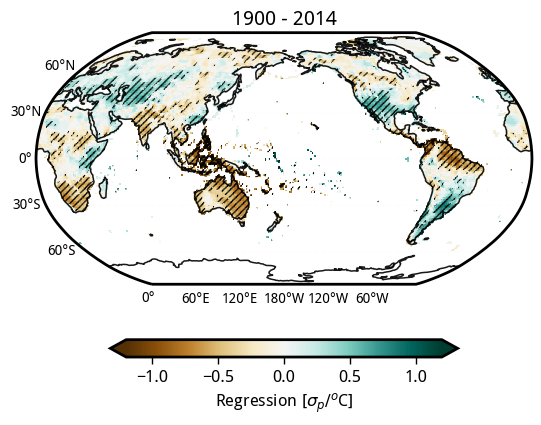

In [73]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
long_regr.plot(vmin=-1.2, cmap='BrBG', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', shrink=0.7, label='Regression [$\sigma_{p}/^{o}$C]'))
xx, yy = np.meshgrid(long_pval.lon, long_pval.lat)
zz = np.ma.masked_greater_equal(long_pval.data, 0.05)
plt.pcolor(xx, yy, zz, hatch='/////', alpha=0., transform=ccrs.PlateCarree())
plt.title('1900 - 2014')
plot_background(ax)
# ax.text(0.1, 0.9, 'a', fontsize=20)
# ax.coastlines()
# gl = ax.gridlines(alpha=0., draw_labels=True)
# gl.top_labels=False
# gl.right_labels=False
# plt.savefig('./images/long_regr_obs.png', dpi=300, bbox_inches='tight')

<GeoAxesSubplot:title={'center':'1900 - 2014'}, xlabel='lon', ylabel='lat'>

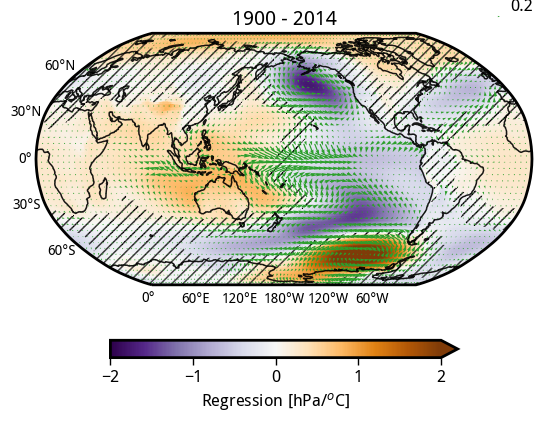

In [65]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(long_regr_rean_psl/100).plot(vmin=-2, cmap='PuOr_r', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', shrink=0.7, label='Regression [hPa/$^{o}$C]'))
xx, yy = np.meshgrid(long_pval_rean_psl.lon, long_pval_rean_psl.lat)
zz = np.ma.masked_less_equal(long_pval_rean_psl.data, 0.05)
plt.pcolor(xx, yy, zz, hatch='///', alpha=0., transform=ccrs.PlateCarree())
long_regr_rean_wind.isel(lon = slice(0, -1, 4), lat = slice(0, -1, 4)).plot.quiver(x='lon', y='lat', u='uwnd', v='vwnd', scale = 45, color='tab:green', transform=ccrs.PlateCarree())
plt.title('1900 - 2014')
plot_background(ax)
# ax.text(0.1, 0.9, 'a', fontsize=20)
# ax.coastlines()
# gl = ax.gridlines(alpha=0., draw_labels=True)
# gl.top_labels=False
# gl.right_labels=False
# plt.savefig('./images/long_regr_obs.png', dpi=300, bbox_inches='tight')

<GeoAxesSubplot:title={'center':'1900 - 2014'}, xlabel='lon', ylabel='lat'>

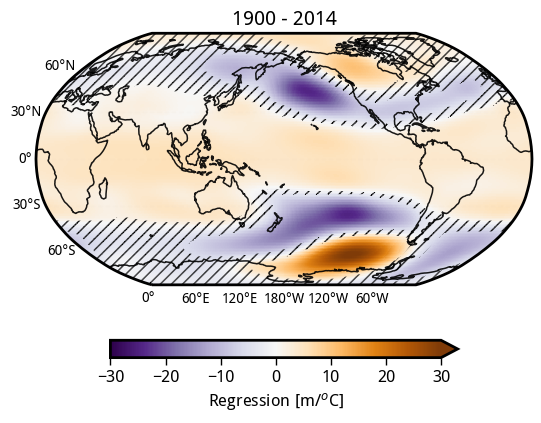

In [113]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(long_regr_rean_zg500 - long_regr_rean_zg500.mean(('lat', 'lon'))).plot(vmin=-30, cmap='PuOr_r', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', shrink=0.7, label='Regression [m/$^{o}$C]'))
xx, yy = np.meshgrid(long_pval_rean_zg500.lon, long_pval_rean_zg500.lat)
zz = np.ma.masked_less_equal(long_pval_rean_zg500.data, 0.05)
plt.pcolor(xx, yy, zz, hatch='///', alpha=0., transform=ccrs.PlateCarree())
plt.title('1900 - 2014')
plot_background(ax)
# ax.text(0.1, 0.9, 'a', fontsize=20)
# ax.coastlines()
# gl = ax.gridlines(alpha=0., draw_labels=True)
# gl.top_labels=False
# gl.right_labels=False
# plt.savefig('./images/long_regr_obs.png', dpi=300, bbox_inches='tight')

Text(0.5, 1.0, 'Max [30yr]')

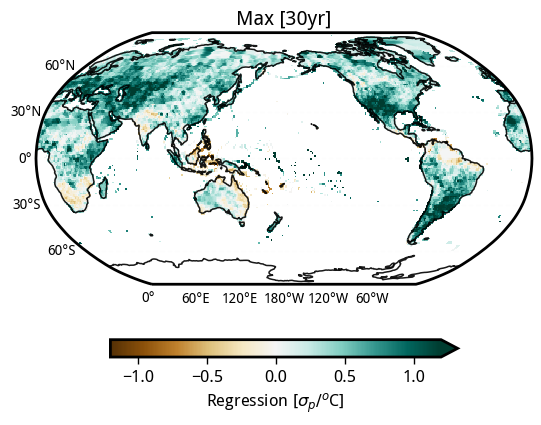

In [65]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
out30.regr.max('ey').plot(vmax=1.2, cmap='BrBG', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', shrink=0.7, label='Regression [$\sigma_{p}/^{o}$C]'))
plot_background(ax)
plt.title('Max [30yr]')
# plt.savefig('./images/max_regr_30y.png', dpi=300, bbox_inches='tight')

Text(0.5, 1.0, 'Min [30yr]')

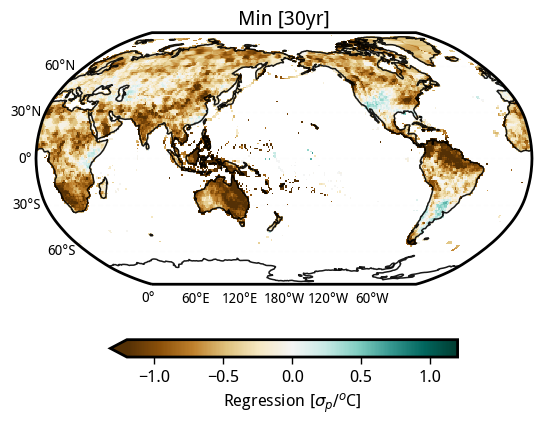

In [66]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
out30.regr.min('ey').plot(vmin=-1.2, cmap='BrBG', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', shrink=0.7, label='Regression [$\sigma_{p}/^{o}$C]'))
plot_background(ax)
plt.title('Min [30yr]')
# plt.savefig('./images/min_regr_30y.png', dpi=300, bbox_inches='tight')

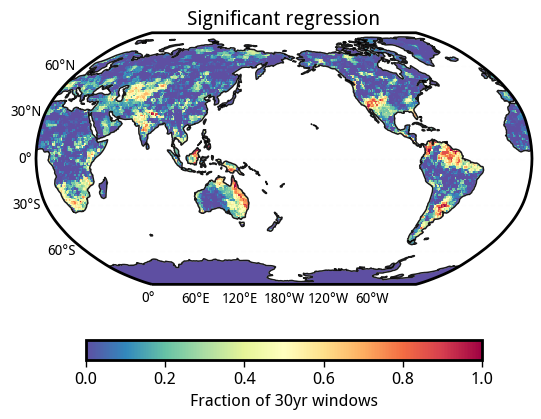

In [72]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
ratio = (out30.pval.where((out30.pval <= 0.05)).count('ey')/len(out30.pval.ey))
ratio.plot(cmap='Spectral_r', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', shrink=0.8, label='Fraction of 30yr windows'))
plot_background(ax)
plt.title('Significant regression')
ax.add_feature(cfeature.OCEAN, zorder=1, color='white')

<GeoAxesSubplot:title={'center':'1900 - 2014'}, xlabel='lon', ylabel='lat'>

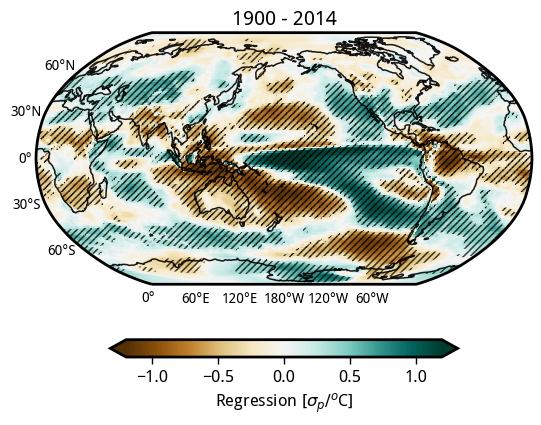

In [232]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
long_regr_rean.plot(vmin=-1.2, cmap='BrBG', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', shrink=0.7, label='Regression [$\sigma_{p}/^{o}$C]'))
xx, yy = np.meshgrid(long_pval_rean.lon, long_pval_rean.lat)
zz = np.ma.masked_greater_equal(long_pval_rean.data, 0.05)
plt.pcolor(xx, yy, zz, hatch='/////', alpha=0., transform=ccrs.PlateCarree())
plt.title('1900 - 2014')
plot_background(ax)
# ax.text(0.1, 0.9, 'a', fontsize=20)
# ax.coastlines()
# gl = ax.gridlines(alpha=0., draw_labels=True)
# gl.top_labels=False
# gl.right_labels=False
# plt.savefig('./images/long_regr_obs.png', dpi=300, bbox_inches='tight')

Text(0.5, 1.0, 'Max [30yr]')

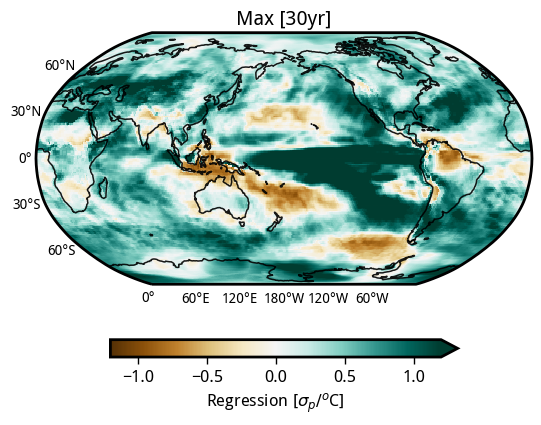

In [233]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
out30_rean.regr.max('ey').plot(vmax=1.2, cmap='BrBG', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', shrink=0.7, label='Regression [$\sigma_{p}/^{o}$C]'))
plot_background(ax)
plt.title('Max [30yr]')
# plt.savefig('./images/max_regr_30y.png', dpi=300, bbox_inches='tight')

Text(0.5, 1.0, 'Min [30yr]')

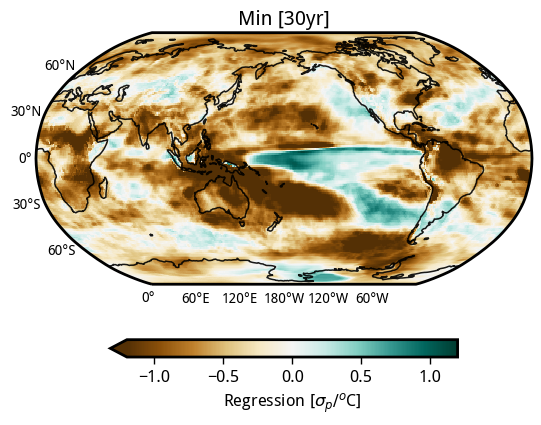

In [234]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
out30_rean.regr.min('ey').plot(vmin=-1.2, cmap='BrBG', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', shrink=0.7, label='Regression [$\sigma_{p}/^{o}$C]'))
plot_background(ax)
plt.title('Min [30yr]')
# plt.savefig('./images/min_regr_30y.png', dpi=300, bbox_inches='tight')

Text(0.5, 1.0, 'Significant regression')

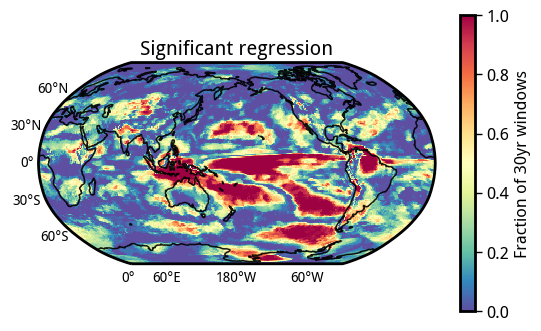

In [235]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
ratio = (out30_rean.pval.where((out30_rean.pval <= 0.05)).count('ey')/len(out30_rean.pval.ey))
ratio.plot(cmap='Spectral_r', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='vertical', shrink=0.8, label='Fraction of 30yr windows'))
plot_background(ax)
plt.title('Significant regression')
# ax.add_feature(cfeature.OCEAN, zorder=1, color='white')

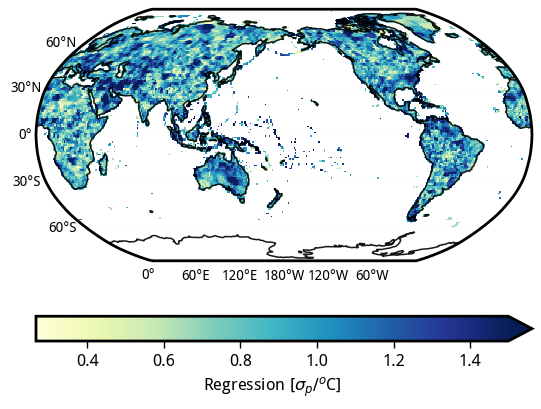

In [91]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(out30.regr.max('ey') - out30.regr.min('ey')).plot(vmax=1.5, cmap='YlGnBu', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
plot_background(ax)
plt.savefig('./images/range_regr_30y.png', dpi=300, bbox_inches='tight')

**Timing of the peaks**

In [236]:
min30_rean = (out30_rean.regr.ey.where((out30_rean.regr == out30_rean.regr.min('ey'))).mean('ey'))#.plot(cmap='PuOr', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Timing of min regression'), robust=True)
max30_rean = (out30_rean.regr.ey.where((out30_rean.regr == out30_rean.regr.max('ey'))).mean('ey'))#.plot(cmap='PuOr', transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Timing of min regression'), robust=True)

In [238]:
timing_min = xr.where(min30_rean < 1975, 1, 0)
timing_max = xr.where(max30_rean < 1975, 1, 0)

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

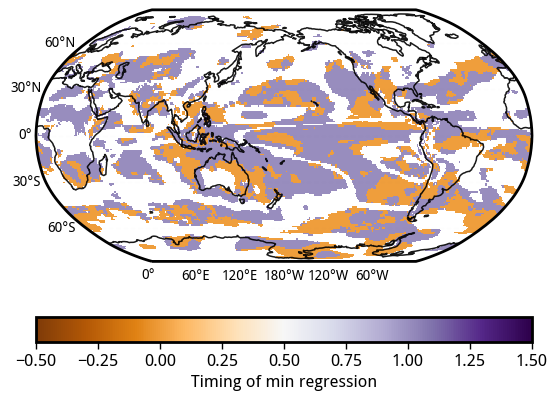

In [244]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(timing_min).where(long_pval_rean < 0.05).plot(cmap='PuOr', vmin=-0.5, vmax=1.5, transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Timing of min regression'), robust=True)
plot_background(ax)
# plt.savefig('./images/range_regr_30y.png', dpi=300, bbox_inches='tight')

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

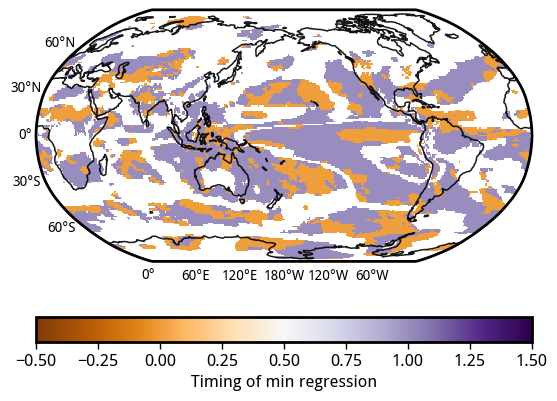

In [245]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(timing_max).where(long_pval_rean < 0.05).plot(cmap='PuOr', vmin=-0.5, vmax=1.5, transform=ccrs.PlateCarree(central_longitude=0), cbar_kwargs=dict(orientation='horizontal', label='Timing of min regression'), robust=True)
plot_background(ax)
# plt.savefig('./images/range_regr_30y.png', dpi=300, bbox_inches='tight')

In [52]:
def calc_windowed_index_strength(index_time_series, duration=30, gap=2, std=False):
    if np.nansum(index_time_series) != 0:
        i = 0
        index_out = []
        ey=[]
        while i < (len(index_time_series.time) - duration):
            if std==False:
                index_out.append(index_time_series.isel(time=slice(i,i+duration)).mean('time').data)
            else:
                index_out.append(index_time_series.isel(time=slice(i,i+duration)).std('time').data)
            ey.append(float(index_time_series.time.dt.year[i+duration]))
            print(f'Completed ey: {float(index_time_series.time.dt.year[i+duration])}', end='\r')
            i += gap

        out = xr.Dataset(
            data_vars=dict(
                index=(["ey"], np.concatenate([arr[np.newaxis, ...] for arr in index_out])),
            ),
            coords=dict(
                ey = ("ey", ey),
            ),
            )

        return out

In [53]:
tpi_da = xr.open_dataset('/g/data/ob22/as8561/data/enso_tele_robustness/tpi.nc')
tpi_da

<xarray.Dataset>
Dimensions:    (time: 1860)
Coordinates:
  * time       (time) datetime64[ns] 1870-01-31 1870-02-28 ... 2024-12-31
Data variables:
    TPI_fil    (time) float64 ...
    TPI_unfil  (time) float64 ...

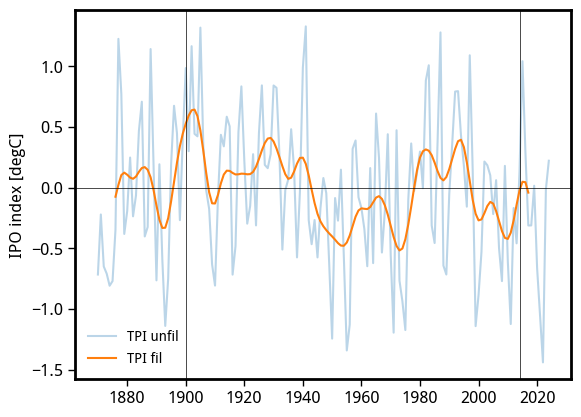

In [54]:
plt.plot(tpi_da.resample(time='1Y').mean('time').time.dt.year, tpi_da.resample(time='1Y').mean('time').TPI_unfil, color='tab:blue', alpha=0.3, label='TPI unfil')
plt.plot(tpi_da.resample(time='1Y').mean('time').time.dt.year, tpi_da.resample(time='1Y').mean('time').TPI_fil, color='tab:orange', label='TPI fil')
plt.axhline(0.0, color='k', lw=0.5)
plt.axvline(1900, color='k', ls='-', lw=0.5)
plt.axvline(2014, color='k', ls='-', lw=0.5)
plt.ylabel('IPO index [degC]')
plt.legend(frameon=False, fontsize=10)

In [55]:
tpi_windows = calc_windowed_index_strength(tpi_da.TPI_unfil.resample(time = 'AS-JUN').mean('time').sel(time = slice('1900', '2014')), duration=30, gap=2)

Text(0, 0.5, 'IPO index [degC]')

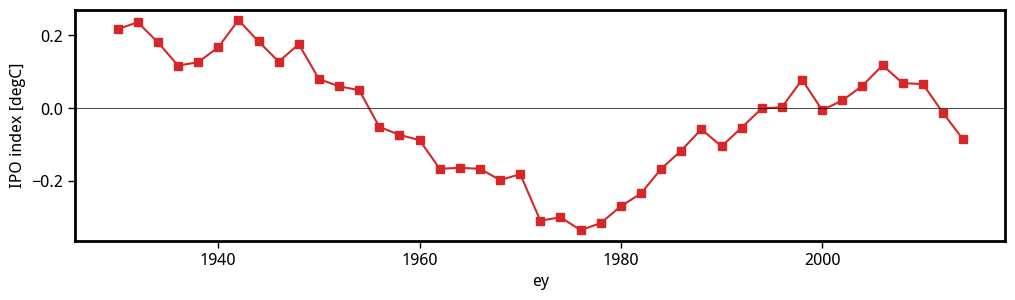

In [56]:
plt.figure(figsize=(12,3))
# (tpi_da.TPI_unfil).resample(time = 'AS-JUN').mean('time').sel(time = slice('1900', '2014')).plot(color='k', alpha=0.1, lw=1.0)
# (tpi_da.TPI_fil).resample(time = 'AS-JUN').mean('time').sel(time = slice('1900', '2014')).plot(lw=2.0, color='tab:red')
(tpi_windows.index).plot(marker='s', color='tab:red')
plt.axhline(0.0, color='k', lw=0.5)
plt.ylabel('IPO index [degC]')

In [57]:
max_ipo_pos = out30.regr.where(tpi_windows.index > tpi_windows.index.std('ey'), drop=True).max('ey')
min_ipo_pos = out30.regr.where(tpi_windows.index > tpi_windows.index.std('ey'), drop=True).min('ey')
max_ipo_neg = out30.regr.where(tpi_windows.index < -tpi_windows.index.std('ey'), drop=True).max('ey')
min_ipo_neg = out30.regr.where(tpi_windows.index < -tpi_windows.index.std('ey'), drop=True).min('ey')

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

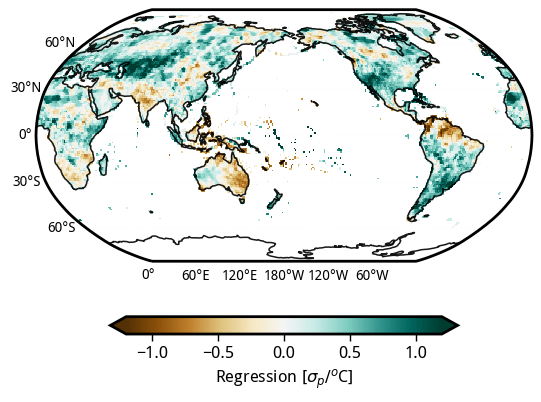

In [58]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(max_ipo_neg).plot(vmin=-1.2, cmap='BrBG', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', shrink=0.7, label='Regression [$\sigma_{p}/^{o}$C]'))
plot_background(ax)
# plt.savefig('./images/range_regr_30y.png', dpi=300, bbox_inches='tight')

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

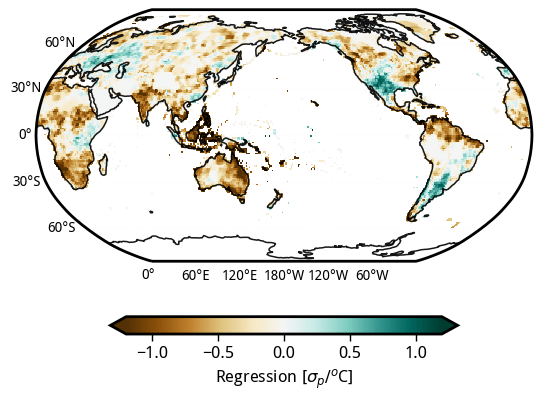

In [59]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
(min_ipo_pos).plot(vmin=-1.2, cmap='BrBG', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', shrink=0.7, label='Regression [$\sigma_{p}/^{o}$C]'))
plot_background(ax)
# plt.savefig('./images/range_regr_30y.png', dpi=300, bbox_inches='tight')

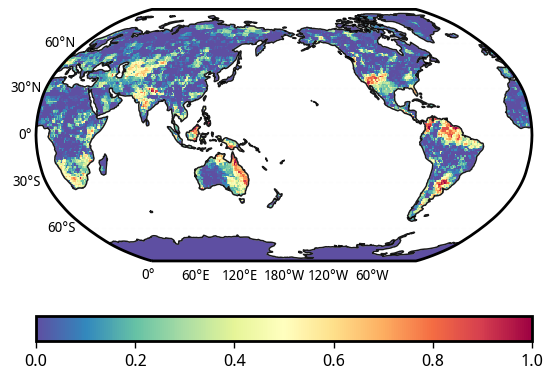

In [112]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
ratio = (out30.pval.where((out30.pval <= 0.05)).count('ey')/len(out30.pval.ey))
ratio.plot(cmap='Spectral_r', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label=''))
plot_background(ax)
ax.add_feature(cfeature.OCEAN, zorder=1, color='white')

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

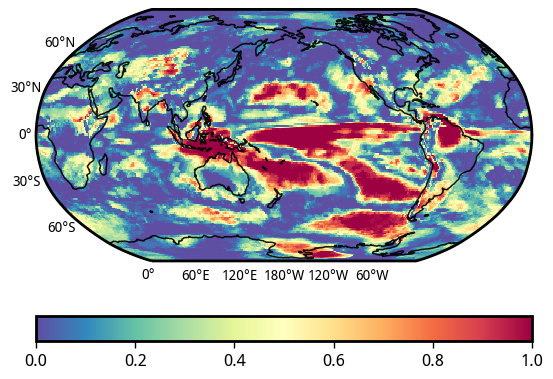

In [113]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
ratio = (out30_rean.pval.where((out30_rean.pval <= 0.05)).count('ey')/len(out30_rean.pval.ey))
ratio.plot(cmap='Spectral_r', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label=''))
plot_background(ax)
# ax.add_feature(cfeature.OCEAN, zorder=1, color='white')

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

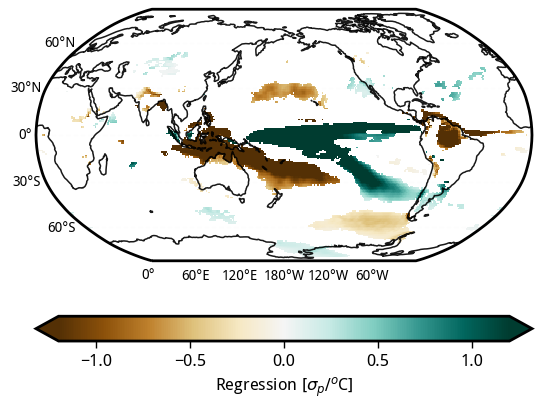

In [117]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
ratio = (out30_rean.pval.where((out30_rean.pval <= 0.05)).count('ey')/len(out30_rean.pval.ey))
long_regr_rean.where(ratio >= 0.6).plot(cmap='BrBG', vmin=-1.2, transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label='Regression [$\sigma_{p}/^{o}$C]'))
plot_background(ax)
# ax.add_feature(cfeature.OCEAN, zorder=1, color='white')

<GeoAxesSubplot:xlabel='lon', ylabel='lat'>

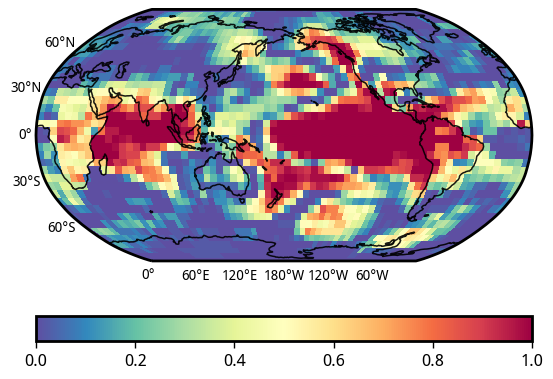

In [115]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
ratio = (out30_ts.regr.where((out30_ts.pval <= 0.05)).count('ey')/len(out30_ts.pval.ey))
ratio.plot(cmap='Spectral_r', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label=''))
plot_background(ax)
# ax.add_feature(cfeature.OCEAN, zorder=1, color='white')

<GeoAxesSubplot:title={'center':'realization = 100'}, xlabel='lon', ylabel='lat'>

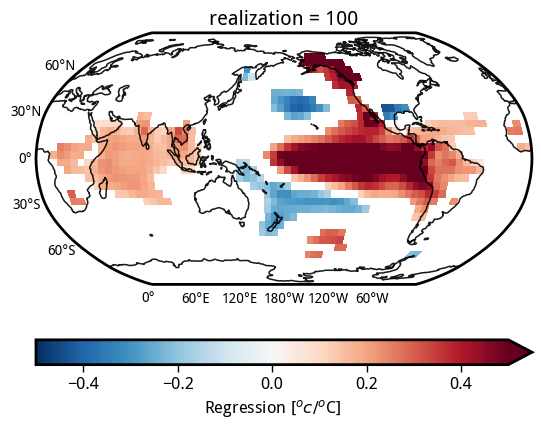

In [119]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
ratio = (out30_ts.pval.where((out30_ts.pval <= 0.05)).count('ey')/len(out30_ts.pval.ey))
long_regr_ts.where(ratio >= 0.6).plot(cmap='RdBu_r', vmin=-0.5, transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', label='Regression [$^{o}c/^{o}$C]'))
plot_background(ax)
# ax.add_feature(cfeature.OCEAN, zorder=1, color='white')

### testing the ACCESS-picontrol

In [20]:
pr_access_pic = (xr.open_mfdataset('/g/data/fs38/publications/CMIP6/CMIP/CSIRO/ACCESS-ESM1-5/piControl/r1i1p1f1/Amon/pr/gn/latest/*.nc').pr*86400*30).load()
ts_access_pic = xr.open_mfdataset('/g/data/fs38/publications/CMIP6/CMIP/CSIRO/ACCESS-ESM1-5/piControl/r1i1p1f1/Amon/ts/gn/latest/*.nc').ts.load()

In [21]:
pr_access_pic_anom = funcs.calc_anom(pr_access_pic, pr_access_pic)
ts_access_pic_anom = funcs.calc_anom(ts_access_pic, ts_access_pic)

In [22]:
weights_pic = np.cos(np.deg2rad(ts_access_pic_anom.lat))
nino34_pic = funcs.detrend_separate_check(ts_access_pic_anom.sel(lat=slice(-5,5), lon = slice(-170+360, -120+360)).weighted(weights_sst_obs).mean(('lat', 'lon')), period=15, dim='time')


In [23]:
import seaborn as sns

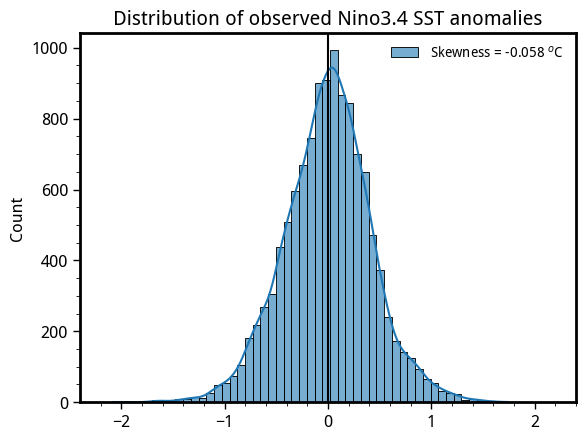

In [24]:
sns.histplot(nino34_pic, bins=51, kde=True, alpha=0.6, color='tab:blue', label=f'Skewness = {np.round(stats.skew(nino34_pic), 3)} $^o$C')
plt.axvline(0.0, color='k', ls='-')
plt.xlim(-2.4, 2.4)
plt.minorticks_on()
plt.title('Distribution of observed Nino3.4 SST anomalies')
plt.legend(frameon=False, fontsize=10)

[Text(1, 0, 'strong-LN'),
 Text(2, 0, 'LN'),
 Text(3, 0, 'NEUT'),
 Text(4, 0, 'EN'),
 Text(5, 0, 'strong-EN')]

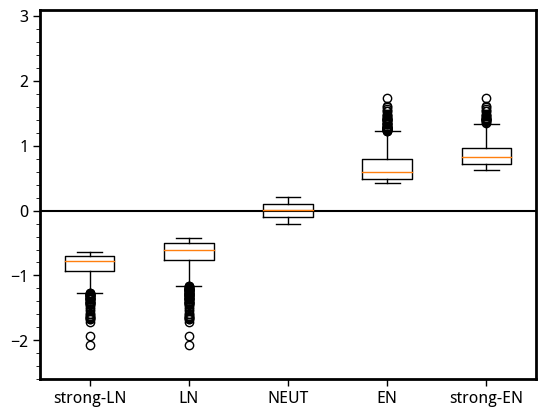

In [25]:
thres = nino34_pic.std('time')
plt.boxplot([nino34_pic.where(nino34_pic < -1.5*thres, drop=True),
             nino34_pic.where(nino34_pic < -thres, drop=True),
             nino34_pic.where((nino34_pic > -0.5*thres) & (nino34_pic < 0.5*thres), drop=True),
             nino34_pic.where(nino34_pic > thres, drop=True),
             nino34_pic.where(nino34_pic > 1.5*thres, drop=True)])


plt.ylim(-2.6, 3.1)
plt.axhline(0.0, color='k', ls='-')
plt.minorticks_on()
plt.tick_params(axis='x', which='minor', bottom=False)
plt.gca().set_xticklabels(['strong-LN', 'LN', 'NEUT', 'EN', 'strong-EN'])

In [26]:
precip_pic_det = funcs.detrend_rolling_window(pr_access_pic_anom.resample(time='AS-JUN').mean('time'), window_size=15)
precip_pic_std = precip_pic_det/precip_pic_det.std('time')

In [27]:
precip_pic_det

<xarray.DataArray 'pr' (time: 1001, lat: 145, lon: 192)>
array([[[-0.60606671, -0.60606671, -0.60606671, ..., -0.60606671,
         -0.60606671, -0.60606671],
        [-0.78002825, -0.77503901, -0.77657152, ..., -0.79790881,
         -0.80774629, -0.79011768],
        [-1.18615575, -1.16940039, -1.15757179, ..., -1.20882734,
         -1.20544019, -1.2003158 ],
        ...,
        [-0.2715363 , -0.20986589, -0.18307985, ..., -0.46803551,
         -0.37323453, -0.2865594 ],
        [-0.3832735 , -0.3594473 , -0.37167358, ..., -0.34917511,
         -0.36007293, -0.38838238],
        [-0.72658224, -0.72658224, -0.72658224, ..., -0.72658224,
         -0.72658224, -0.72658224]],

       [[-1.08042014, -1.08042014, -1.08042014, ..., -1.08042014,
         -1.08042014, -1.08042014],
        [-0.84629593, -0.83903728, -0.80581574, ..., -0.88801783,
         -0.85710734, -0.84428343],
        [-0.38470648, -0.35103047, -0.31221607, ..., -0.44964523,
         -0.41781044, -0.40633194],
...
        [-2.94022449, -2.88167826, -2.85740053, ..., -3.20157724,
         -3.14148655, -3.01987231],
        [-2.09083203, -2.19170411, -2.22778492, ..., -2.06554538,
         -2.00360964, -1.96838087],
        [-1.78457351, -1.78457351, -1.78457351, ..., -1.78457351,
         -1.78457351, -1.78457351]],

       [[-0.24878445, -0.24878445, -0.24878445, ..., -0.24878445,
         -0.24878445, -0.24878445],
        [-0.57856635, -0.57929196, -0.576004  , ..., -0.56907435,
         -0.57102032, -0.57414787],
        [-0.72215429, -0.71024695, -0.69325627, ..., -0.74272547,
         -0.74092173, -0.73382744],
        ...,
        [ 1.67705522,  1.59512287,  1.54652897, ...,  1.65747945,
          1.74374476,  1.65082017],
        [ 0.70310081,  0.80226926,  0.78874675, ...,  0.76322356,
          0.70544013,  0.7020078 ],
        [ 0.23262576,  0.23262576,  0.23262576, ...,  0.23262576,
          0.23262576,  0.23262576]]])
Coordinates:
  * lat      (lat) float64 -90.0 -88.75 -87.5 -86.25 ... 86.25 87.5 88.75 90.0
  * lon      (lon) float64 0.0 1.875 3.75 5.625 7.5 ... 352.5 354.4 356.2 358.1
  * time     (time) object 0100-06-01 00:00:00 ... 1100-06-01 00:00:00

In [164]:
long_regr_pic = funcs.get_regr(nino34_pic.resample(time = 'AS-JUN').mean('time'), precip_pic_std, dim='time')
long_pval_pic = funcs.get_pval(nino34_pic.resample(time = 'AS-JUN').mean('time'), precip_pic_std, dim='time')

In [299]:
test = calc_tele_diversity(precip_pic_std, nino34_pic.resample(time = 'AS-JUN').mean('time'), duration=100, gap=100)

In [300]:
test.to_netcdf('/g/data/ob22/as8561/data/enso_tele_robustness/out100_pic10.nc')

#### regional

In [28]:
weights_pic = np.cos(np.deg2rad(precip_pic_std.lat))
weights_pic

<xarray.DataArray 'lat' (lat: 145)>
array([6.12323400e-17, 2.18148850e-02, 4.36193874e-02, 6.54031292e-02,
       8.71557427e-02, 1.08866875e-01, 1.30526192e-01, 1.52123386e-01,
       1.73648178e-01, 1.95090322e-01, 2.16439614e-01, 2.37685892e-01,
       2.58819045e-01, 2.79829014e-01, 3.00705800e-01, 3.21439465e-01,
       3.42020143e-01, 3.62438038e-01, 3.82683432e-01, 4.02746690e-01,
       4.22618262e-01, 4.42288690e-01, 4.61748613e-01, 4.80988769e-01,
       5.00000000e-01, 5.18773258e-01, 5.37299608e-01, 5.55570233e-01,
       5.73576436e-01, 5.91309648e-01, 6.08761429e-01, 6.25923472e-01,
       6.42787610e-01, 6.59345815e-01, 6.75590208e-01, 6.91513056e-01,
       7.07106781e-01, 7.22363962e-01, 7.37277337e-01, 7.51839807e-01,
       7.66044443e-01, 7.79884483e-01, 7.93353340e-01, 8.06444604e-01,
       8.19152044e-01, 8.31469612e-01, 8.43391446e-01, 8.54911871e-01,
       8.66025404e-01, 8.76726756e-01, 8.87010833e-01, 8.96872742e-01,
       9.06307787e-01, 9.15311479e-01, 9.23879533e-01, 9.32007869e-01,
       9.39692621e-01, 9.46930129e-01, 9.53716951e-01, 9.60049854e-01,
       9.65925826e-01, 9.71342070e-01, 9.76296007e-01, 9.80785280e-01,
       9.84807753e-01, 9.88361510e-01, 9.91444861e-01, 9.94056338e-01,
       9.96194698e-01, 9.97858923e-01, 9.99048222e-01, 9.99762027e-01,
       1.00000000e+00, 9.99762027e-01, 9.99048222e-01, 9.97858923e-01,
       9.96194698e-01, 9.94056338e-01, 9.91444861e-01, 9.88361510e-01,
       9.84807753e-01, 9.80785280e-01, 9.76296007e-01, 9.71342070e-01,
       9.65925826e-01, 9.60049854e-01, 9.53716951e-01, 9.46930129e-01,
       9.39692621e-01, 9.32007869e-01, 9.23879533e-01, 9.15311479e-01,
       9.06307787e-01, 8.96872742e-01, 8.87010833e-01, 8.76726756e-01,
       8.66025404e-01, 8.54911871e-01, 8.43391446e-01, 8.31469612e-01,
       8.19152044e-01, 8.06444604e-01, 7.93353340e-01, 7.79884483e-01,
       7.66044443e-01, 7.51839807e-01, 7.37277337e-01, 7.22363962e-01,
       7.07106781e-01, 6.91513056e-01, 6.75590208e-01, 6.59345815e-01,
       6.42787610e-01, 6.25923472e-01, 6.08761429e-01, 5.91309648e-01,
       5.73576436e-01, 5.55570233e-01, 5.37299608e-01, 5.18773258e-01,
       5.00000000e-01, 4.80988769e-01, 4.61748613e-01, 4.42288690e-01,
       4.22618262e-01, 4.02746690e-01, 3.82683432e-01, 3.62438038e-01,
       3.42020143e-01, 3.21439465e-01, 3.00705800e-01, 2.79829014e-01,
       2.58819045e-01, 2.37685892e-01, 2.16439614e-01, 1.95090322e-01,
       1.73648178e-01, 1.52123386e-01, 1.30526192e-01, 1.08866875e-01,
       8.71557427e-02, 6.54031292e-02, 4.36193874e-02, 2.18148850e-02,
       6.12323400e-17])
Coordinates:
  * lat      (lat) float64 -90.0 -88.75 -87.5 -86.25 ... 86.25 87.5 88.75 90.0
Attributes:
    bounds:         lat_bnds
    units:          degrees_north
    axis:           Y
    long_name:      Latitude
    standard_name:  latitude

In [29]:
import regionmask

In [30]:
ar6_mask_pic = regionmask.defined_regions.ar6.all.mask_3D(precip_pic_std)

In [31]:
reg = precip_pic_std.where(ar6_mask_pic.isel(region=39)).weighted(weights_pic).mean(('lat', 'lon'))

In [38]:
# test1 = calc_tele_diversity1d(reg.isel(time = slice(0, 100)), nino34_pic.resample(time = 'AS-JUN').mean('time').isel(time = slice(0, 100)), duration=30, gap=2)
test1 = calc_tele_diversity1d(reg, nino34_pic.resample(time = 'AS-JUN').mean('time'), duration=100, gap=10)

In [39]:
# test2 = calc_tele_diversity1d(reg.isel(time = slice(-100, -1)), nino34_pic.resample(time = 'AS-JUN').mean('time').isel(time = slice(-100, -1)), duration=30, gap=2)
test2 = calc_tele_diversity1d(reg, nino34_pic.resample(time = 'AS-JUN').mean('time'), duration=100, gap=100)

In [40]:
test1.regr.to_numpy()

array([-0.88460307, -0.94900635, -0.94538757, -0.85091271, -0.76266091,
       -0.76302875, -0.68050154, -0.58583493, -0.61992444, -0.65154714,
       -0.5842671 , -0.56562472, -0.62500404, -0.56898818, -0.59844743,
       -0.48982858, -0.43702857, -0.60960886, -0.52656367, -0.50763153,
       -0.50305418, -0.44504788, -0.36866557, -0.37149181, -0.45485147,
       -0.44151668, -0.49925873, -0.40951186, -0.59433028, -0.61563373,
       -0.65676101, -0.74297592, -0.82973183, -0.88344266, -0.76427069,
       -0.77836916, -0.79644365, -0.76710542, -0.71375827, -0.68286098,
       -0.72150475, -0.59904255, -0.67697332, -0.72543104, -0.84936295,
       -0.86069626, -0.94197902, -0.98394882, -0.87610894, -0.77202417,
       -0.73901017, -0.95788356, -0.92364587, -0.79251105, -0.61606744,
       -0.5683177 , -0.48383264, -0.51584376, -0.5318391 , -0.65175457,
       -0.72734958, -0.63271518, -0.56922023, -0.62182301, -0.72892645,
       -0.79384679, -0.8630803 , -0.90041349, -0.84120786, -0.78

In [41]:
test2.regr.to_numpy()

array([-0.88460307, -0.5842671 , -0.50305418, -0.65676101, -0.72150475,
       -0.73901017, -0.72734958, -0.64878129, -0.6108871 , -0.8387041 ])

In [124]:
test = xr.open_dataset('/g/data/ob22/as8561/data/enso_tele_robustness/out100_pic10.nc')

In [301]:
nino34_windows = calc_windowed_index_strength(nino34_pic.resample(time = 'AS-JUN').mean('time'), duration=100, gap=100, std=True)

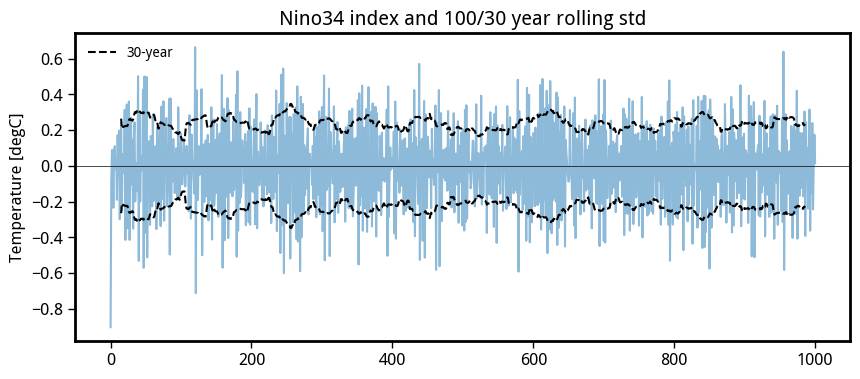

In [298]:
plt.figure(figsize=(10,4))
timex = nino34_pic.resample(time='AS-JUN').mean('time').time.dt.year - 100
plt.plot(timex, nino34_pic.resample(time = 'AS-JUN').mean('time'), alpha=0.5)
# plt.plot(timex, nino34_pic.resample(time = 'AS-JUN').mean('time').rolling(time=100, center=True).std('time'), color='tab:gray', label='100-year')
plt.plot(timex, nino34_pic.resample(time = 'AS-JUN').mean('time').rolling(time=30, center=True).std('time'), color='k', ls='--', label='30-year')
# nino34_windows.index.plot(marker='^', color='tab:red', ms=5)
# plt.plot(timex, (-nino34_pic.resample(time = 'AS-JUN').mean('time').rolling(time=100, center=True).std('time')), color='tab:gray')
plt.plot(timex, (-nino34_pic.resample(time = 'AS-JUN').mean('time').rolling(time=30, center=True).std('time')), color='k', ls='--')
# (-nino34_windows.index).plot(marker='v', color='tab:red', ms=5)
plt.axhline(0.0, color='k', lw=0.5)
plt.ylabel('Temperature [degC]')
plt.title('Nino34 index and 100/30 year rolling std')
plt.legend(frameon=False, fontsize=10)

<GeoAxesSubplot:title={'center':'ACCESS piControl 1000-years'}, xlabel='lon', ylabel='lat'>

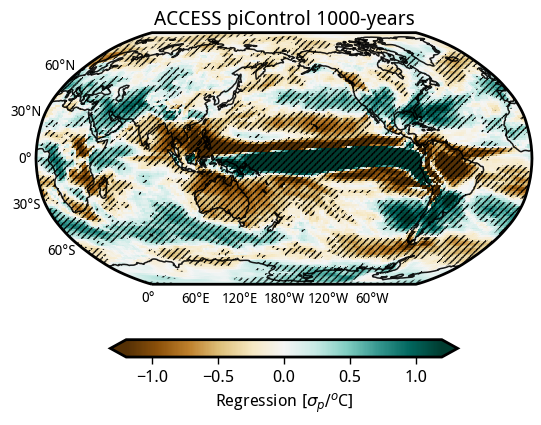

In [ ]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
long_regr_pic.plot(vmin=-1.2, cmap='BrBG', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', shrink=0.7, label='Regression [$\sigma_{p}/^{o}$C]'))
xx, yy = np.meshgrid(long_pval_pic.lon, long_pval_pic.lat)
zz = np.ma.masked_greater_equal(long_pval_pic.data, 0.05)
plt.pcolor(xx, yy, zz, hatch='/////', alpha=0., transform=ccrs.PlateCarree())
plt.title('ACCESS piControl 1000-years')
plot_background(ax)
# ax.text(0.1, 0.9, 'a', fontsize=20)
# ax.coastlines()
# gl = ax.gridlines(alpha=0., draw_labels=True)
# gl.top_labels=False
# gl.right_labels=False
# plt.savefig('./images/long_regr_obs.png', dpi=300, bbox_inches='tight')

<GeoAxesSubplot:title={'center':'Max [100 yr]'}, xlabel='lon', ylabel='lat'>

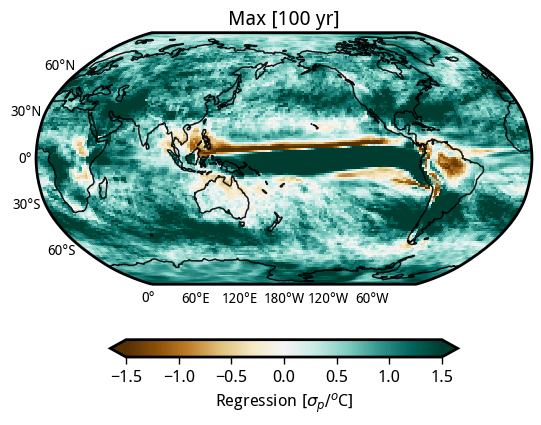

In [121]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
test.regr.max('ey').plot(vmax=1.5, cmap='BrBG', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', shrink=0.7, label='Regression [$\sigma_{p}/^{o}$C]'))
# xx, yy = np.meshgrid(long_pval_pic.lon, long_pval_pic.lat)
# zz = np.ma.masked_greater_equal(long_pval_pic.data, 0.05)
# plt.pcolor(xx, yy, zz, hatch='/////', alpha=0., transform=ccrs.PlateCarree())
plt.title('Max [100 yr]')
plot_background(ax)
# ax.text(0.1, 0.9, 'a', fontsize=20)
# ax.coastlines()
# gl = ax.gridlines(alpha=0., draw_labels=True)
# gl.top_labels=False
# gl.right_labels=False
# plt.savefig('./images/long_regr_obs.png', dpi=300, bbox_inches='tight')

<GeoAxesSubplot:title={'center':'Min [100 yr]'}, xlabel='lon', ylabel='lat'>

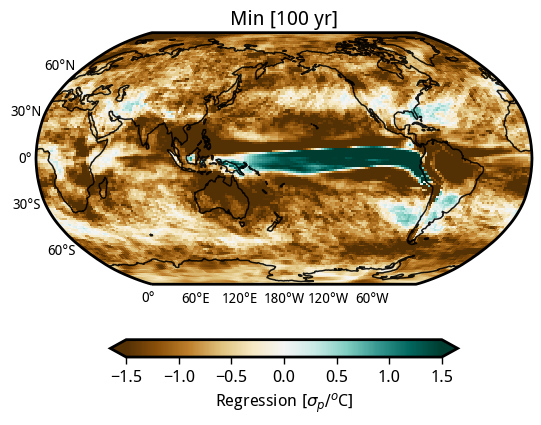

In [122]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
test.regr.min('ey').plot(vmin=-1.5, cmap='BrBG', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', shrink=0.7, label='Regression [$\sigma_{p}/^{o}$C]'))
# xx, yy = np.meshgrid(long_pval_pic.lon, long_pval_pic.lat)
# zz = np.ma.masked_greater_equal(long_pval_pic.data, 0.05)
# plt.pcolor(xx, yy, zz, hatch='/////', alpha=0., transform=ccrs.PlateCarree())
plt.title('Min [100 yr]')
plot_background(ax)
# ax.text(0.1, 0.9, 'a', fontsize=20)
# ax.coastlines()
# gl = ax.gridlines(alpha=0., draw_labels=True)
# gl.top_labels=False
# gl.right_labels=False
# plt.savefig('./images/long_regr_obs.png', dpi=300, bbox_inches='tight')

<GeoAxesSubplot:title={'center':'Difference b/w random subsequent\n 100-year values'}, xlabel='lon', ylabel='lat'>

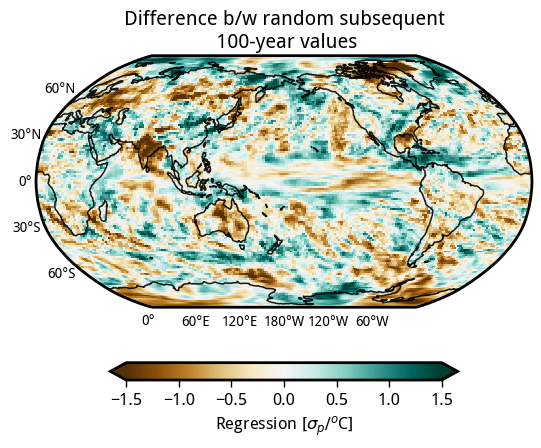

In [128]:
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
test.regr.diff(dim='ey').isel(ey=7).plot(vmin=-1.5, cmap='BrBG', transform=ccrs.PlateCarree(), cbar_kwargs=dict(orientation='horizontal', shrink=0.7, label='Regression [$\sigma_{p}/^{o}$C]'))
# xx, yy = np.meshgrid(long_pval_pic.lon, long_pval_pic.lat)
# zz = np.ma.masked_greater_equal(long_pval_pic.data, 0.05)
# plt.pcolor(xx, yy, zz, hatch='/////', alpha=0., transform=ccrs.PlateCarree())
plt.title('Difference b/w random subsequent'+
          '\n 100-year values')
plot_background(ax)
# ax.text(0.1, 0.9, 'a', fontsize=20)
# ax.coastlines()
# gl = ax.gridlines(alpha=0., draw_labels=True)
# gl.top_labels=False
# gl.right_labels=False
# plt.savefig('./images/long_regr_obs.png', dpi=300, bbox_inches='tight')